# What makes a Test bowler's average low?

**Question:** among bowlers with 100+ Test wickets, which attributes go with a low bowling average over their **first 100 Test wickets**?

**Pipeline**
1. Parse every Test match in `all_male_json/` (Cricsheet) into one ball-by-ball table.
2. Pick bowlers with 100+ Test bowler-wickets and cut each one's deliveries at the 100th wicket → `Test First 100 Wickets.csv`.
3. Attach the dismissed batter's form going into each wicket → `test_wicket_context.csv`.
4. Aggregate to one row per bowler → `test_bowler_features.csv`.
5. Analyse: decomposition of the average, univariate correlations, a multivariate model, a conditions-adjusted view and robustness checks.

Run top to bottom from the project folder with the `data_work` kernel. It takes about a minute.

## 0. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb as db
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneOut, RepeatedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

PROJECT_DIR = Path.cwd()
JSON_DIR = PROJECT_DIR / 'all_male_json'

WICKET_WINDOW = 100            # features and target are measured over each bowler's first N Test wickets
MIN_CAREER_WICKETS = 100       # bowlers need at least this many Test wickets in the data
FULL_COVERAGE_FROM = '2007-01-01'  # Cricsheet's Test coverage is patchy before this date (see section 1)

# Dismissals credited to the bowler (run outs, retirements, obstruction etc. are not)
BOWLER_WICKET_KINDS = ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket')
# Kinds that do not count as a batting dismissal
NON_DISMISSAL_KINDS = ('retired hurt', 'retired not out')

N_BOOT = 2000
RNG = np.random.default_rng(42)

## 1. Build the Test ball-by-ball table
Same parsing approach as the original notebook, restricted to `info.match_type == 'Test'`.
Every delivery becomes a row. Each dismissal also goes to a separate `dismissals` table, because one ball can (rarely) carry two wickets.

In [2]:
deliveries, dismissals, matches = [], [], []

for file_path in sorted(JSON_DIR.glob('*.json')):
    with open(file_path, 'r') as f:
        match_data = json.load(f)

    info = match_data.get('info', {})
    if info.get('match_type') != 'Test':
        continue

    match_id = int(file_path.stem)
    registry = info.get('registry', {}).get('people', {})
    teams = info.get('teams', [])
    outcome = info.get('outcome', {})

    matches.append({
        'match_id': match_id,
        'test_number': info.get('match_type_number'),
        'date': info.get('dates', [None])[0],
        'venue': info.get('venue'),
        'city': info.get('city'),
        'team_1': teams[0],
        'team_2': teams[1],
        'winner': outcome.get('winner'),
        'result': outcome.get('result', 'win' if outcome.get('winner') else None),
    })

    for innings_num, innings in enumerate(match_data.get('innings', []), start=1):
        batting_team = innings.get('team')
        bowling_team = [t for t in teams if t != batting_team][0]

        for over in innings.get('overs', []):
            over_num = over.get('over')

            for ball_num, delivery in enumerate(over.get('deliveries', []), start=1):
                extras = delivery.get('extras', {})
                runs = delivery.get('runs', {})
                wickets = delivery.get('wickets', [])
                bowler_wicket = next((w for w in wickets if w.get('kind') in BOWLER_WICKET_KINDS), None)
                first_wicket = wickets[0] if wickets else None

                deliveries.append({
                    'match_id': match_id,
                    'match_type': 'Test',
                    'date': info.get('dates', [None])[0],
                    'venue': info.get('venue'),
                    'batting_team': batting_team,
                    'bowling_team': bowling_team,
                    'innings': innings_num,
                    'over': over_num,
                    'ball': ball_num,
                    'bowler_id': registry.get(delivery.get('bowler')),
                    'bowler': delivery.get('bowler'),
                    'batter_id': registry.get(delivery.get('batter')),
                    'batter': delivery.get('batter'),
                    'non_striker_id': registry.get(delivery.get('non_striker')),
                    'non_striker': delivery.get('non_striker'),
                    'runs_batter': runs.get('batter', 0),
                    'runs_extras': runs.get('extras', 0),
                    'runs_total': runs.get('total', 0),
                    'wides': extras.get('wides', 0),
                    'noballs': extras.get('noballs', 0),
                    'byes': extras.get('byes', 0),
                    'legbyes': extras.get('legbyes', 0),
                    'penalty': extras.get('penalty', 0),
                    'is_wicket': int(bowler_wicket is not None),   # bowler-credited wicket on this ball
                    'wicket_kind': (bowler_wicket or first_wicket or {}).get('kind'),
                    'player_out': (bowler_wicket or first_wicket or {}).get('player_out'),
                    'player_out_id': registry.get((bowler_wicket or first_wicket or {}).get('player_out')),
                })

                for w in wickets:
                    dismissals.append({
                        'match_id': match_id,
                        'innings': innings_num,
                        'over': over_num,
                        'ball': ball_num,
                        'player_out_id': registry.get(w.get('player_out')),
                        'kind': w.get('kind'),
                    })

matches = pd.DataFrame(matches)
matches['date'] = pd.to_datetime(matches['date'])

df = pd.DataFrame(deliveries)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['date', 'match_id', 'innings', 'over', 'ball']).reset_index(drop=True)
df['seq'] = np.arange(len(df))   # global chronological order of deliveries

dismissals = pd.DataFrame(dismissals).merge(
    df[['match_id', 'innings', 'over', 'ball', 'seq']], on=['match_id', 'innings', 'over', 'ball'], how='left'
)

print(f'{len(matches)} Tests, {len(df):,} deliveries, {len(dismissals):,} dismissals')
print('Date range:', df['date'].min().date(), 'to', df['date'].max().date())

894 Tests, 1,721,188 deliveries, 28,783 dismissals
Date range: 2001-12-19 to 2026-08-27


#### Batting position
Same logic as the original notebook. A batter's position is the order in which they first appear at the crease (as striker or non-striker) in that innings.

In [3]:
strikers = df[['match_id', 'innings', 'seq', 'batter_id']].rename(columns={'batter_id': 'player_id'})
strikers['tiebreak'] = 0  # striker counted before non-striker on the same ball

non_strikers = df[['match_id', 'innings', 'seq', 'non_striker_id']].rename(columns={'non_striker_id': 'player_id'})
non_strikers['tiebreak'] = 1

appearances = pd.concat([strikers, non_strikers], ignore_index=True).sort_values(['match_id', 'innings', 'seq', 'tiebreak'])
first_appearance = appearances.drop_duplicates(subset=['match_id', 'innings', 'player_id'], keep='first').copy()
first_appearance['batting_position'] = first_appearance.groupby(['match_id', 'innings']).cumcount() + 1

position_lookup = first_appearance[['match_id', 'innings', 'player_id', 'batting_position']]
df = df.merge(position_lookup.rename(columns={'player_id': 'batter_id'}), on=['match_id', 'innings', 'batter_id'], how='left')
df = df.sort_values('seq').reset_index(drop=True)
df['batting_position'].value_counts().sort_index()

batting_position
1     227423
2     213016
3     240699
4     234595
5     222421
6     182448
7     150225
8     105591
9      71425
10     48143
11     25191
12        11
Name: count, dtype: int64

#### Coverage check
Cricsheet does not hold every Test. `match_type_number` is the official Test number, so comparing the count held with the range of Test numbers in each year shows how complete each year is.
Coverage is patchy before 2007, so a bowler whose first Test in the data is earlier may have debuted before the data starts, or have missing matches inside their first-100 window. Those bowlers are flagged as **censored**, left out of the main analysis, and added back in a robustness check.

In [4]:
coverage = (
    matches.assign(year=matches['date'].dt.year)
    .groupby('year')
    .agg(tests_held=('match_id', 'count'), first_no=('test_number', 'min'), last_no=('test_number', 'max'))
)
coverage['tests_played_approx'] = coverage['last_no'] - coverage['first_no'] + 1
coverage['coverage_pct'] = (100 * coverage['tests_held'] / coverage['tests_played_approx']).round(0)
coverage

,tests_held,first_no,last_no,tests_played_approx,coverage_pct
year,,,,,
2001,1,1578,1578,1,100.0
2002,2,1634,1635,2,100.0
2003,20,1636,1675,40,50.0
2004,17,1680,1726,47,36.0
2005,24,1732,1779,48,50.0
2006,39,1780,1825,46,85.0
2007,30,1826,1856,31,97.0
2008,43,1857,1902,46,93.0
2009,41,1904,1944,41,100.0


## 2. Select bowlers and cut each one at their 100th Test wicket
Fixes compared with the original notebook's query:
* the running count is partitioned by `bowler_id`, not by name;
* only bowler-credited dismissals count (no run outs) when selecting bowlers and when counting to 100;
* the window keeps every delivery up to and including the ball of the 100th wicket.

In [5]:
query = f'''
WITH career AS (
    SELECT bowler_id
         , SUM(is_wicket) AS career_wickets
         , MIN(date) AS first_test_in_data
    FROM df
    GROUP BY bowler_id
    HAVING SUM(is_wicket) >= {MIN_CAREER_WICKETS}
)

, numbered AS (
    SELECT d.*
         , c.career_wickets
         , c.first_test_in_data
         , SUM(d.is_wicket) OVER (PARTITION BY d.bowler_id ORDER BY d.seq ROWS UNBOUNDED PRECEDING) AS wickets_taken
    FROM df d
    JOIN career c ON d.bowler_id = c.bowler_id
)

SELECT *
FROM numbered
WHERE wickets_taken - is_wicket < {WICKET_WINDOW}
ORDER BY seq
'''

first_100 = db.sql(query).df()

wickets_per_bowler = first_100.groupby('bowler_id')['is_wicket'].sum()
assert (wickets_per_bowler == WICKET_WINDOW).all(), 'every bowler should have exactly WICKET_WINDOW wickets in the window'
assert (first_100['match_type'] == 'Test').all()

print(f'{first_100["bowler_id"].nunique()} bowlers, {len(first_100):,} deliveries in their first {WICKET_WINDOW} Test wickets')

71 bowlers, 414,911 deliveries in their first 100 Test wickets


In [6]:
export_cols = ['match_id', 'date', 'venue', 'batting_team', 'bowling_team', 'innings', 'over', 'ball', 'bowler_id', 'bowler',
               'batter_id', 'batter', 'batting_position', 'non_striker_id', 'non_striker', 'runs_batter', 'runs_extras',
               'runs_total', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'is_wicket', 'wicket_kind', 'wickets_taken',
               'match_type']
first_100[export_cols].to_csv('Test First 100 Wickets.csv', index=False)

#### Player metadata (scraped from Cricinfo by `scrape_player_styles.py`)
The parsing helpers are copied from the original notebook.

In [7]:
def parse_batting_hand(batting_style):
    if pd.isna(batting_style):
        return None
    s = batting_style.lower()
    if 'left' in s:
        return 'left'
    if 'right' in s:
        return 'right'
    return None


def parse_bowling_style(bowling_style_full):
    if pd.isna(bowling_style_full):
        return None, None

    # Multiple styles are comma-separated — keep only the first
    first_style = bowling_style_full.split(',')[0].strip().lower()

    if 'left-arm' in first_style:
        hand = 'left'
    elif 'right-arm' in first_style:
        hand = 'right'
    else:
        # "legbreak" / "legbreak googly" never state an arm in Cricinfo's convention,
        # because leg-spin is (near-)exclusively bowled right-arm.
        hand = 'right'

    style = (
        first_style
        .replace('right-arm', '')
        .replace('left-arm', '')
        .replace('slow', '')
        .strip()
    )
    return hand, style


def batting_position_label(batting_position):
    if batting_position in [1, 2, 3]: return 'top-order'
    elif batting_position in [4, 5, 6, 7]: return 'middle-order'
    else: return 'tailender'


SPIN_TYPES = ('orthodox', 'offbreak', 'legbreak', 'legbreak googly', 'wrist-spin', 'chinaman')

player_styles = pd.read_csv('player_styles.csv')
player_styles['date_of_birth'] = pd.to_datetime(player_styles['date_of_birth'], errors='coerce')
player_styles = player_styles.drop_duplicates('identifier', keep='last').set_index('identifier')

bowler_ids = first_100['bowler_id'].unique()
missing_styles = [b for b in bowler_ids if b not in player_styles.index or pd.isna(player_styles.loc[b, 'bowling_style'])]
print('Bowlers missing scraped style/DOB:', missing_styles)

Bowlers missing scraped style/DOB: []


## 3. Who did they dismiss? Batter form going into each wicket
For every batter in the Test data we build career figures **entering each match**: runs, dismissals, balls faced and innings batted in all earlier Tests.
Figures *before the ball* would mix in the current innings, so a batter dismissed on 150 would look like a better player.
The current innings is captured separately as runs and balls at the moment of dismissal.

Career averages from only a few innings are noisy, so each one is shrunk toward the typical average for the batter's position band, using 5 pseudo-dismissals:
`shrunk_avg = (runs + 5 × band_avg) / (dismissals + 5)`.

In [8]:
legal_for_batter = (df['wides'] == 0).astype(int)   # no-balls count as balls faced, wides do not
df['ball_faced'] = legal_for_batter

valid_dismissals = dismissals[~dismissals['kind'].isin(NON_DISMISSAL_KINDS)]

batter_match = (
    df.groupby(['batter_id', 'match_id'], as_index=False)
    .agg(date=('date', 'first'), runs=('runs_batter', 'sum'), balls=('ball_faced', 'sum'))
)
innings_batted = (
    appearances.drop_duplicates(['match_id', 'innings', 'player_id'])
    .groupby(['player_id', 'match_id']).size().rename('innings_batted').reset_index()
    .rename(columns={'player_id': 'batter_id'})
)
outs = valid_dismissals.groupby(['player_out_id', 'match_id']).size().rename('outs').reset_index().rename(columns={'player_out_id': 'batter_id'})

batter_match = (
    batter_match.merge(innings_batted, on=['batter_id', 'match_id'], how='outer')
    .merge(outs, on=['batter_id', 'match_id'], how='left')
)
batter_match['date'] = batter_match['date'].fillna(batter_match['match_id'].map(matches.set_index('match_id')['date']))
batter_match[['runs', 'balls', 'innings_batted', 'outs']] = batter_match[['runs', 'balls', 'innings_batted', 'outs']].fillna(0)
batter_match = batter_match.sort_values(['batter_id', 'date', 'match_id'])

g = batter_match.groupby('batter_id')
for col in ['runs', 'balls', 'innings_batted', 'outs']:
    batter_match[f'prior_{col}'] = g[col].cumsum() - batter_match[col]   # totals from earlier Tests only
batter_match['prior_tests'] = g.cumcount()

# Each batter's usual position band (mode across their innings), used for the shrinkage prior
usual_band = (
    first_appearance.assign(band=first_appearance['batting_position'].apply(batting_position_label))
    .groupby('player_id')['band'].agg(lambda s: s.mode().iloc[0])
)

In [9]:
wickets = first_100[first_100['is_wicket'] == 1].copy()

# Score and balls faced by the dismissed batter in this innings, up to and including the wicket ball
df['innings_runs_so_far'] = df.groupby(['match_id', 'innings', 'batter_id'])['runs_batter'].cumsum()
df['innings_balls_so_far'] = df.groupby(['match_id', 'innings', 'batter_id'])['ball_faced'].cumsum()
wickets = wickets.merge(df[['seq', 'innings_runs_so_far', 'innings_balls_so_far']], on='seq', how='left')

wickets = wickets.merge(
    batter_match[['batter_id', 'match_id', 'prior_runs', 'prior_balls', 'prior_innings_batted', 'prior_outs', 'prior_tests']]
    .rename(columns={'batter_id': 'player_out_id'}),
    on=['player_out_id', 'match_id'], how='left'
)
wickets['batter_band'] = wickets['player_out_id'].map(usual_band)

band_avg = (
    batter_match.assign(band=batter_match['batter_id'].map(usual_band))
    .groupby('band').apply(lambda x: x['runs'].sum() / x['outs'].sum(), include_groups=False)
)
print('Runs per dismissal by usual batting band:\n', band_avg.round(1))

K_SHRINK = 5
prior_mean = wickets['batter_band'].map(band_avg)
wickets['batter_career_avg_shrunk'] = (wickets['prior_runs'] + K_SHRINK * prior_mean) / (wickets['prior_outs'] + K_SHRINK)
wickets['batter_career_sr'] = np.where(wickets['prior_balls'] >= 100, 100 * wickets['prior_runs'] / wickets['prior_balls'].clip(lower=1), np.nan)
wickets['batter_position_band'] = wickets['batting_position'].apply(batting_position_label)

# Dismissed batter's age and hand
wickets['batter_dob'] = wickets['player_out_id'].map(player_styles['date_of_birth'])
wickets['batter_age'] = (wickets['date'] - wickets['batter_dob']).dt.days / 365.25
wickets['batter_hand'] = wickets['player_out_id'].map(player_styles['batting_style']).apply(parse_batting_hand)

# Bowler's own innings number in the match (1st or 2nd time bowling), as in the original notebook
first_100['bowler_innings'] = (
    first_100.groupby(['match_id', 'bowler_id'])['innings'].rank(method='dense').astype(int)
)
wickets = wickets.merge(first_100[['seq', 'bowler_innings']], on='seq', how='left')

wicket_context_cols = ['match_id', 'date', 'venue', 'innings', 'bowler_innings', 'over', 'ball', 'bowler_id', 'bowler',
                       'player_out_id', 'player_out', 'batting_position', 'batter_position_band', 'wicket_kind', 'batter_hand',
                       'batter_age', 'innings_runs_so_far', 'innings_balls_so_far', 'prior_tests', 'prior_innings_batted',
                       'prior_runs', 'prior_outs', 'batter_career_avg_shrunk', 'batter_career_sr']
wickets[wicket_context_cols].to_csv('test_wicket_context.csv', index=False)
wickets[wicket_context_cols].head()

Runs per dismissal by usual batting band:
 band
middle-order    37.8
tailender       15.0
top-order       36.5
dtype: float64


,match_id,date,venue,innings,bowler_innings,over,ball,bowler_id,bowler,player_out_id,player_out,batting_position,batter_position_band,wicket_kind,batter_hand,batter_age,innings_runs_so_far,innings_balls_so_far,prior_tests,prior_innings_batted,prior_runs,prior_outs,batter_career_avg_shrunk,batter_career_sr
0,63963,2001-12-19,"M Chinnaswamy Stadium, Bangalore",1,1,123,3,0c2730df,A Kumble,dc0f5506,MJ Hoggard,11,tailender,lbw,right,24.966461,1,10,0,0,0.0,0.0,14.957213,NaN
1,63963,2001-12-19,"M Chinnaswamy Stadium, Bangalore",2,1,3,3,ddc0828d,A Flintoff,96d3958e,D Dasgupta,2,top-order,caught,right,24.533881,0,7,0,0,0.0,0.0,36.536732,NaN
2,63963,2001-12-19,"M Chinnaswamy Stadium, Bangalore",2,1,9,3,ddc0828d,A Flintoff,de8cce37,VVS Laxman,3,top-order,bowled,right,27.132101,12,18,0,0,0.0,0.0,37.821505,NaN
3,63963,2001-12-19,"M Chinnaswamy Stadium, Bangalore",2,1,35,3,ddc0828d,A Flintoff,2975a46c,SS Das,1,top-order,bowled,right,24.120465,28,105,0,0,0.0,0.0,36.536732,NaN
4,63963,2001-12-19,"M Chinnaswamy Stadium, Bangalore",2,1,53,5,dc0f5506,MJ Hoggard,0184dc35,R Dravid,5,middle-order,caught,right,28.936345,3,61,0,0,0.0,0.0,36.536732,NaN


## 4. Bowler-level features
Everything is measured over each bowler's first-100-wicket window.

* **Legal balls** exclude wides and no-balls.
* **Bowler runs** = `runs_total − byes − legbyes − penalty`.
* **Average** = bowler runs / 100.
* **Strike rate (SR)** = legal balls / wicket.
* **Economy** = bowler runs per 6 legal balls.

With these definitions, **average = SR × economy / 6** holds exactly.

In [10]:
w = first_100.copy()
w['legal_ball'] = ((w['wides'] == 0) & (w['noballs'] == 0)).astype(int)
w['bowler_runs'] = w['runs_total'] - w['byes'] - w['legbyes'] - w['penalty']
w['dot_ball'] = ((w['legal_ball'] == 1) & (w['bowler_runs'] == 0)).astype(int)
w['boundary'] = w['runs_batter'].isin([4, 6]).astype(int)
w['batter_hand'] = w['batter_id'].map(player_styles['batting_style']).apply(parse_batting_hand)
w['to_lhb'] = (w['batter_hand'] == 'left').astype(int)

per_over = (
    w.groupby(['bowler_id', 'match_id', 'innings', 'over'])
    .agg(legal=('legal_ball', 'sum'), runs=('bowler_runs', 'sum'))
)
per_over['maiden'] = ((per_over['legal'] >= 6) & (per_over['runs'] == 0)).astype(int)
maidens = per_over.groupby('bowler_id')['maiden'].mean().rename('maiden_rate')

base = w.groupby('bowler_id').agg(
    bowler=('bowler', 'last'),
    team=('bowling_team', lambda s: s.mode().iloc[0]),
    career_wickets_in_data=('career_wickets', 'first'),
    first_test_in_data=('first_test_in_data', 'first'),
    window_end=('date', 'max'),
    matches_to_100=('match_id', 'nunique'),
    deliveries=('match_id', 'size'),
    legal_balls=('legal_ball', 'sum'),
    bowler_runs=('bowler_runs', 'sum'),
    wides=('wides', 'sum'), noballs=('noballs', 'sum'), byes=('byes', 'sum'), legbyes=('legbyes', 'sum'),
    dot_balls=('dot_ball', 'sum'),
    boundaries=('boundary', 'sum'),
    balls_to_lhb=('to_lhb', 'mean'),
    unique_opponents=('batting_team', 'nunique'),
)
base = base.join(maidens)

feat = pd.DataFrame(index=base.index)
feat['bowler'] = base['bowler']
feat['team'] = base['team']
feat['average'] = base['bowler_runs'] / WICKET_WINDOW
feat['strike_rate'] = base['legal_balls'] / WICKET_WINDOW
feat['economy'] = 6 * base['bowler_runs'] / base['legal_balls']
feat['log_average'] = np.log(feat['average'])
assert np.allclose(feat['average'], feat['strike_rate'] * feat['economy'] / 6)

# Bowler attributes
style = player_styles.reindex(feat.index)
feat['bowling_style_raw'] = style['bowling_style']
parsed = style['bowling_style'].apply(lambda s: pd.Series(parse_bowling_style(s), index=['bowling_arm', 'bowling_type']))
feat = feat.join(parsed)
feat['is_spinner'] = feat['bowling_type'].isin(SPIN_TYPES).astype(int)
feat['is_left_arm'] = (feat['bowling_arm'] == 'left').astype(int)
feat['bowler_bats_left'] = (style['batting_style'].apply(parse_batting_hand) == 'left').astype(int)
feat['first_test_in_data'] = pd.to_datetime(base['first_test_in_data'])
feat['debut_year'] = feat['first_test_in_data'].dt.year
feat['age_at_first_test'] = (feat['first_test_in_data'] - style['date_of_birth']).dt.days / 365.25
feat['censored'] = (feat['first_test_in_data'] < pd.Timestamp(FULL_COVERAGE_FROM)).astype(int)

# Output / pace of accumulation (mechanically tied to SR)
feat['matches_to_100'] = base['matches_to_100']
feat['overs_to_100'] = base['legal_balls'] / 6
feat['balls_per_match'] = base['legal_balls'] / base['matches_to_100']

# Control
feat['dot_ball_pct'] = 100 * base['dot_balls'] / base['legal_balls']
feat['boundary_pct'] = 100 * base['boundaries'] / base['legal_balls']
feat['maiden_rate'] = base['maiden_rate']

# Extras per 100 deliveries
for col in ['wides', 'noballs', 'byes', 'legbyes']:
    feat[f'{col}_per_100'] = 100 * base[col] / base['deliveries']

feat['unique_opponents'] = base['unique_opponents']
feat['balls_to_lhb_pct'] = 100 * base['balls_to_lhb']

#### Wicket-mix features (from `test_wicket_context`)

In [11]:
wk = wickets.groupby('bowler_id')
feat['lhb_wicket_pct'] = 100 * wk['batter_hand'].apply(lambda s: (s == 'left').mean())
feat['lhb_wicket_minus_exposure'] = feat['lhb_wicket_pct'] - feat['balls_to_lhb_pct']

for band in ['top-order', 'middle-order', 'tailender']:
    feat[f'{band}_wicket_pct'] = 100 * wk['batter_position_band'].apply(lambda s, b=band: (s == b).mean())

kind_map = {'caught': 'caught', 'caught and bowled': 'caught_and_bowled', 'bowled': 'bowled', 'lbw': 'lbw', 'stumped': 'stumped'}
for kind, name in kind_map.items():
    feat[f'{name}_pct'] = 100 * wk['wicket_kind'].apply(lambda s, k=kind: (s == k).mean())
feat['bowled_or_lbw_pct'] = feat['bowled_pct'] + feat['lbw_pct']

feat['second_bowling_innings_wicket_pct'] = 100 * wk['bowler_innings'].apply(lambda s: (s == 2).mean())

feat['dismissed_batter_age'] = wk['batter_age'].mean()
feat['dismissed_batter_career_avg'] = wk['batter_career_avg_shrunk'].mean()
feat['dismissed_batter_career_sr'] = wk['batter_career_sr'].mean()
feat['dismissed_batter_prior_tests'] = wk['prior_tests'].mean()
feat['dismissed_batter_innings_runs'] = wk['innings_runs_so_far'].mean()
feat['dismissed_batter_innings_balls'] = wk['innings_balls_so_far'].mean()
feat['dismissed_batter_innings_sr'] = 100 * wk['innings_runs_so_far'].sum() / wk['innings_balls_so_far'].sum()
feat['quality_wicket_pct'] = 100 * wk['batter_career_avg_shrunk'].apply(lambda s: (s >= 40).mean())

#### Conditions and context
* **Match environment:** runs per wicket conceded by every *other* bowler (both teams) in the same matches. It captures pitches, era and opposition all at once.
* **Venue environment:** the long-run runs per wicket at the venues the bowler played, excluding the bowler's own deliveries, weighted by balls bowled there.
* **Opposition strength:** runs per wicket that the batting teams faced scored against all other bowlers in the same calendar year, weighted by balls bowled to them.
* **Team strength:** win and draw rate of the bowler's team in the window's matches.
* **Workload share:** the bowler's share of their team's legal balls in those matches.

In [12]:
df['legal_ball'] = ((df['wides'] == 0) & (df['noballs'] == 0)).astype(int)
df['bowler_runs'] = df['runs_total'] - df['byes'] - df['legbyes'] - df['penalty']
df['year'] = df['date'].dt.year

def runs_per_wicket(runs, wkts):
    return runs / wkts.where(wkts > 0)

# Match environment: everyone else in the bowler's window matches
match_bowler = df.groupby(['match_id', 'bowler_id']).agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'), legal=('legal_ball', 'sum')).reset_index()
match_tot = match_bowler.groupby('match_id')[['runs', 'wkts']].sum()
team_balls = df.groupby(['match_id', 'bowling_team'])['legal_ball'].sum()

window_matches = w[['bowler_id', 'match_id', 'bowling_team']].drop_duplicates()
wm = window_matches.merge(match_bowler, on=['match_id', 'bowler_id'], how='left')
wm = wm.join(match_tot, on='match_id', rsuffix='_match')
wm['other_runs'] = wm['runs_match'] - wm['runs']
wm['other_wkts'] = wm['wkts_match'] - wm['wkts']
wm['team_balls'] = [team_balls.get((m, t), np.nan) for m, t in zip(wm['match_id'], wm['bowling_team'])]
wm = wm.merge(matches[['match_id', 'winner', 'result']], on='match_id', how='left')
wm['won'] = (wm['winner'] == wm['bowling_team']).astype(int)
wm['drawn'] = (wm['result'] == 'draw').astype(int)

mg = wm.groupby('bowler_id')
feat['match_env_avg'] = mg['other_runs'].sum() / mg['other_wkts'].sum()
feat['team_ball_share_pct'] = 100 * mg['legal'].sum() / mg['team_balls'].sum()
feat['team_win_pct'] = 100 * mg['won'].mean()
feat['team_draw_pct'] = 100 * mg['drawn'].mean()

# Venue environment (all years), excluding the bowler's own deliveries
venue_tot = df.groupby('venue').agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'))
bv = df[df['bowler_id'].isin(feat.index)].groupby(['bowler_id', 'venue']).agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'))
wv = w.groupby(['bowler_id', 'venue'])['legal_ball'].sum().rename('balls_in_window').reset_index()
wv = wv.join(venue_tot, on='venue').join(bv, on=['bowler_id', 'venue'], rsuffix='_own')
wv['venue_rpw_ex_bowler'] = runs_per_wicket(wv['runs'] - wv['runs_own'], wv['wkts'] - wv['wkts_own'])
feat['venue_env_avg'] = wv.dropna(subset=['venue_rpw_ex_bowler']).groupby('bowler_id').apply(
    lambda x: np.average(x['venue_rpw_ex_bowler'], weights=x['balls_in_window']), include_groups=False)

# Opposition strength: batting team's runs per wicket that year against all other bowlers
team_year = df.groupby(['batting_team', 'year']).agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'))
bty = df[df['bowler_id'].isin(feat.index)].groupby(['bowler_id', 'batting_team', 'year']).agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'))
w['year'] = w['date'].dt.year
wo = w.groupby(['bowler_id', 'batting_team', 'year'])['legal_ball'].sum().rename('balls_in_window').reset_index()
wo = wo.join(team_year, on=['batting_team', 'year']).join(bty, on=['bowler_id', 'batting_team', 'year'], rsuffix='_own')
wo['opp_rpw_ex_bowler'] = runs_per_wicket(wo['runs'] - wo['runs_own'], wo['wkts'] - wo['wkts_own'])
feat['opposition_batting_avg'] = wo.dropna(subset=['opp_rpw_ex_bowler']).groupby('bowler_id').apply(
    lambda x: np.average(x['opp_rpw_ex_bowler'], weights=x['balls_in_window']), include_groups=False)

# Conditions-adjusted average: the bowler's average relative to everyone else in the same matches
feat['relative_average'] = feat['average'] / feat['match_env_avg']

# Whole-career figures in the data, for the robustness check
career = df[df['bowler_id'].isin(feat.index)].groupby('bowler_id').agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'))
feat['career_average_in_data'] = career['runs'] / career['wkts']
feat['career_wickets_in_data'] = base['career_wickets_in_data']

feat = feat.reset_index().rename(columns={'index': 'bowler_id'})
feat.to_csv('test_bowler_features.csv', index=False)
print(feat.shape)
print('Censored (first Test in data before', FULL_COVERAGE_FROM + '):', feat.loc[feat['censored'] == 1, 'bowler'].tolist())
feat.sort_values('average').head(10)

(71, 58)
Censored (first Test in data before 2007-01-01): ['CS Martin', 'Danish Kaneria', 'A Kumble', 'Umar Gul', 'M Ntini', 'JE Taylor', 'M Muralitharan', 'MS Panesar', 'M Morkel', 'JH Kallis', 'Harbhajan Singh', 'DW Steyn', 'Z Khan', 'FH Edwards', 'SK Warne', 'SJ Harmison', 'JM Anderson', 'HMRKB Herath', 'DL Vettori', 'MJ Hoggard', 'B Lee', 'A Flintoff']


,bowler_id,bowler,team,average,strike_rate,economy,log_average,bowling_style_raw,bowling_arm,bowling_type,is_spinner,is_left_arm,bowler_bats_left,first_test_in_data,debut_year,age_at_first_test,censored,matches_to_100,overs_to_100,balls_per_match,dot_ball_pct,boundary_pct,maiden_rate,wides_per_100,noballs_per_100,byes_per_100,legbyes_per_100,unique_opponents,balls_to_lhb_pct,lhb_wicket_pct,lhb_wicket_minus_exposure,top-order_wicket_pct,middle-order_wicket_pct,tailender_wicket_pct,caught_pct,caught_and_bowled_pct,bowled_pct,lbw_pct,stumped_pct,bowled_or_lbw_pct,second_bowling_innings_wicket_pct,dismissed_batter_age,dismissed_batter_career_avg,dismissed_batter_career_sr,dismissed_batter_prior_tests,dismissed_batter_innings_runs,dismissed_batter_innings_balls,dismissed_batter_innings_sr,quality_wicket_pct,match_env_avg,team_ball_share_pct,team_win_pct,team_draw_pct,venue_env_avg,opposition_batting_avg,relative_average,career_average_in_data,career_wickets_in_data
53,cfe70281,VD Philander,South Africa,17.40,37.92,2.753165,2.856470,right-arm fast-medium,right,fast-medium,0,0,0,2011-11-09,2011,26.376454,0,19,632.000000,199.578947,79.219409,5.748945,0.242902,0.441788,1.117464,0.441788,1.299376,6,25.415800,27.0,1.584200,39.0,37.0,24.0,67.0,1.0,14.0,18.0,0.0,32.0,46.0,28.983600,34.261467,51.383809,27.95,18.25,39.98,45.647824,36.0,37.129310,22.461082,63.157895,26.315789,32.945592,32.092918,0.468632,22.321429,224.0
22,4ba44e19,M Muralitharan,Sri Lanka,18.40,40.94,2.696629,2.912351,right-arm offbreak,right,offbreak,1,0,0,2003-12-18,2003,31.668720,1,14,682.333333,292.428571,76.624328,5.227162,0.228863,0.000000,0.438063,1.825262,1.387199,6,39.644682,36.0,-3.644682,20.0,56.0,24.0,48.0,4.0,13.0,26.0,9.0,39.0,49.0,27.677043,32.619711,52.982876,7.47,26.42,50.61,52.203122,27.0,34.759760,35.233733,57.142857,7.142857,33.897147,34.948743,0.529348,22.847737,243.0
38,8fd1a8f5,DW Steyn,South Africa,19.73,33.68,3.514846,2.982140,right-arm fast,right,fast,0,0,0,2006-04-15,2006,22.800821,1,18,561.333333,187.111111,75.296912,8.165083,0.187279,0.519931,2.310803,1.097631,2.050838,6,34.199884,25.0,-9.199884,32.0,37.0,31.0,56.0,4.0,20.0,20.0,0.0,40.0,53.0,27.868063,29.334339,51.051730,9.56,18.80,36.52,51.478642,21.0,35.189130,20.981450,61.111111,16.666667,33.634167,29.060256,0.560684,22.415313,431.0
46,bb18be76,SK Warne,Australia,21.55,43.69,2.959487,3.070376,legbreak googly,right,legbreak googly,1,0,0,2004-03-08,2004,34.483231,1,17,728.166667,257.000000,74.937057,5.676356,0.171196,0.296398,0.182399,0.752394,0.934793,8,30.255358,33.0,2.744642,28.0,33.0,39.0,57.0,3.0,16.0,20.0,4.0,36.0,51.0,28.227023,34.751928,55.309646,6.58,24.00,50.05,47.952048,39.0,34.432735,29.124483,70.588235,17.647059,33.258349,36.523506,0.625858,23.814815,135.0
61,ded9240e,PJ Cummins,Australia,21.79,46.59,2.806182,3.081451,right-arm fast,right,fast,0,0,0,2011-11-17,2011,18.527036,0,21,776.500000,221.857143,78.235673,6.009873,0.220796,0.917627,0.085361,0.896287,0.917627,5,34.229620,32.0,-2.229620,34.0,41.0,25.0,83.0,2.0,10.0,5.0,0.0,15.0,47.0,29.008816,34.054243,52.188867,39.79,24.71,53.26,46.395043,33.0,33.338596,21.361889,52.380952,14.285714,33.342769,31.246583,0.653597,21.913043,322.0
19,462411b3,JJ Bumrah,India,22.95,51.52,2.672748,3.133318,right-arm fast,right,fast,0,0,0,2018-01-05,2018,24.082136,0,24,858.666667,214.666667,79.095497,5.357143,0.240741,0.498084,1.034483,1.302682,1.130268,5,39.616858,34.0,-5.616858,30.0,44.0,26.0,47.0,1.0,23.0,29.0,0.0,52.0,44.0,29.345599,33.825296,50.533411,43.07,20.08,45.94,43.709186,26.0,26.966150,23.573403,41.666667,12.500000,30.999184,28.680094,0.851067,19.790598,234.0
8,12eddf28,RJ Harris,Australia,22.97,48.41,2.846932,3.134189,right-arm fast,right,fast,0,0,0,2010-03-19,2010,30.436687,0,24,806.833333,201.708333,79.177856,6.321008,0.254007,0.205465,0.328745,0.636943,1.397165,6,36.983768,37.0,0.016232,36.0,38.0,26.0,64.0,1.0,21.0,14.0,0.0,35.0,52.0,29.823463,35.736020,50.293527,41.64,22.69,47.53,47.738271,44.0,33.055060,21.304534,62.500000,12.50000

## 5. Analysis
The main sample leaves out censored bowlers. Throughout, a **lower** average is better.

In [13]:
main = feat[feat['censored'] == 0].copy()
print(f'Main sample: {len(main)} bowlers (pace {int((main.is_spinner == 0).sum())}, spin {int(main.is_spinner.sum())})')
main[['average', 'strike_rate', 'economy', 'matches_to_100', 'match_env_avg', 'relative_average']].describe().round(2)

Main sample: 49 bowlers (pace 32, spin 17)


,average,strike_rate,economy,matches_to_100,match_env_avg,relative_average
count,49.00,49.00,49.00,49.00,49.00,49.00
mean,29.96,57.69,3.12,27.84,33.00,0.92
std,5.00,8.14,0.33,6.19,3.19,0.17
min,17.40,37.92,2.27,17.00,26.97,0.47
25%,27.26,53.63,2.89,24.00,30.78,0.80
50%,30.03,57.45,3.14,27.00,32.89,0.90
75%,32.96,62.37,3.34,31.00,35.16,1.05
max,44.12,81.60,3.84,44.00,39.95,1.29


In [14]:
main['first_test'] = main['first_test_in_data'].dt.date.astype(str)
cols_show = ['bowler', 'team', 'bowling_type', 'first_test', 'matches_to_100', 'average', 'strike_rate', 'economy', 'relative_average']
print('Lowest averages to 100 wickets')
display(main.sort_values('average')[cols_show].head(10).round(2))
print('Highest averages to 100 wickets')
display(main.sort_values('average', ascending=False)[cols_show].head(10).round(2))

Lowest averages to 100 wickets


,bowler,team,bowling_type,first_test,matches_to_100,average,strike_rate,economy,relative_average
53,VD Philander,South Africa,fast-medium,2011-11-09,19,17.40,37.92,2.75,0.47
61,PJ Cummins,Australia,fast,2011-11-17,21,21.79,46.59,2.81,0.65
19,JJ Bumrah,India,fast,2018-01-05,24,22.95,51.52,2.67,0.85
8,RJ Harris,Australia,fast,2010-03-19,24,22.97,48.41,2.85,0.69
42,Mohammad Abbas,Pakistan,medium-fast,2017-04-21,27,22.99,55.42,2.49,0.75
65,K Rabada,South Africa,fast,2015-11-05,21,23.11,40.45,3.43,0.75
18,Shaheen Shah Afridi,Pakistan,fast,2018-12-03,26,24.65,48.66,3.04,0.72
70,RA Jadeja,India,orthodox,2012-12-13,24,24.68,65.16,2.27,0.75
24,Nauman Ali,Pakistan,orthodox,2021-01-26,22,25.24,49.02,3.09,0.80
0,JR Hazlewood,Australia,fast-medium,2014-12-17,25,25.79,53.75,2.88,0.72


Highest averages to 100 wickets


,bowler,team,bowling_type,first_test,matches_to_100,average,strike_rate,economy,relative_average
13,RAS Lakmal,Sri Lanka,fast-medium,2010-11-23,44,44.12,81.60,3.24,1.29
47,MM Ali,England,offbreak,2014-06-12,38,41.47,66.98,3.71,1.28
51,UT Yadav,India,fast,2011-11-06,37,36.05,59.93,3.61,1.06
67,SCJ Broad,England,fast-medium,2007-12-09,34,35.94,68.77,3.14,0.99
45,AS Joseph,West Indies,fast,2016-08-09,35,35.88,58.27,3.69,1.27
32,D Bishoo,West Indies,legbreak,2011-05-12,27,35.81,66.86,3.21,1.18
20,CBRLS Kumara,Sri Lanka,fast,2016-10-29,33,35.67,55.74,3.84,1.06
33,Shakib Al Hasan,Bangladesh,orthodox,2007-05-18,31,34.27,69.75,2.95,0.97
15,MJ Leach,England,orthodox,2018-03-30,30,34.19,69.78,2.94,1.19
50,Mehedi Hasan Miraz,Bangladesh,offbreak,2016-10-20,24,34.19,62.37,3.29,1.07


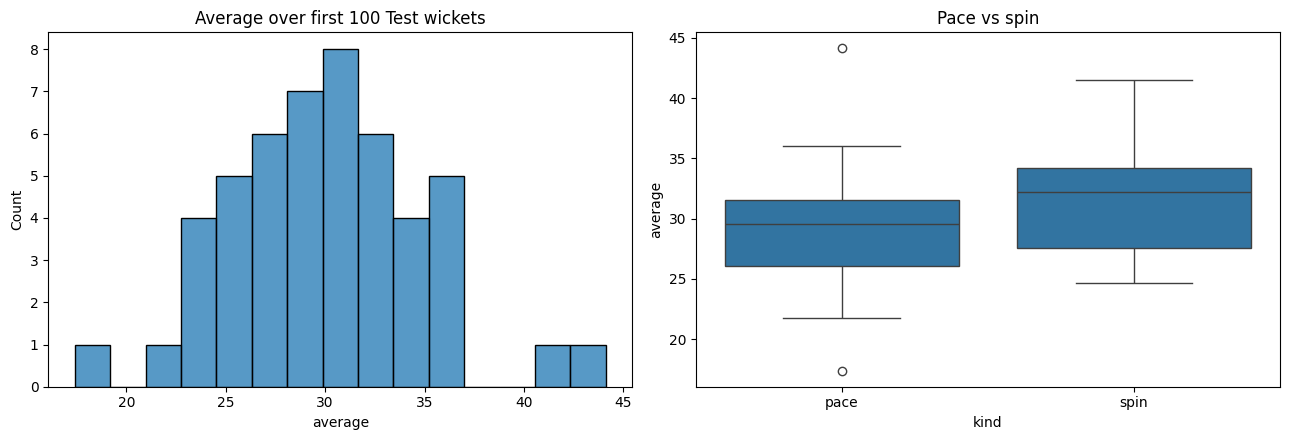

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(main, x='average', bins=15, ax=ax[0])
ax[0].set_title('Average over first 100 Test wickets')
sns.boxplot(main.assign(kind=np.where(main.is_spinner == 1, 'spin', 'pace')), x='kind', y='average', ax=ax[1])
ax[1].set_title('Pace vs spin')
plt.tight_layout()

### 5.1 Strike rate or economy? Decomposing the average
Since `log(average) = log(SR) + log(economy) − log(6)`, the spread of log-average across bowlers splits exactly into an SR part, an economy part and their covariance.

In [16]:
def decompose(frame):
    ls, le, la = np.log(frame['strike_rate']), np.log(frame['economy']), frame['log_average']
    var_a = la.var()
    return pd.Series({
        'var_log_avg': var_a,
        'share_from_SR': ls.var() / var_a,
        'share_from_economy': le.var() / var_a,
        'share_from_covariance': 2 * np.cov(ls, le)[0, 1] / var_a,
        'corr_SR_economy': np.corrcoef(ls, le)[0, 1],
        'spearman_avg_SR': stats.spearmanr(frame['average'], frame['strike_rate'])[0],
        'spearman_avg_econ': stats.spearmanr(frame['average'], frame['economy'])[0],
    })

decomp = pd.DataFrame({
    'all': decompose(main),
    'pace': decompose(main[main.is_spinner == 0]),
    'spin': decompose(main[main.is_spinner == 1]),
}).round(3)
decomp

,all,pace,spin
var_log_avg,0.029,0.034,0.018
share_from_SR,0.705,0.638,0.588
share_from_economy,0.399,0.332,0.652
share_from_covariance,-0.104,0.029,-0.241
corr_SR_economy,-0.098,0.032,-0.194
spearman_avg_SR,0.720,0.754,0.602
spearman_avg_econ,0.523,0.587,0.508


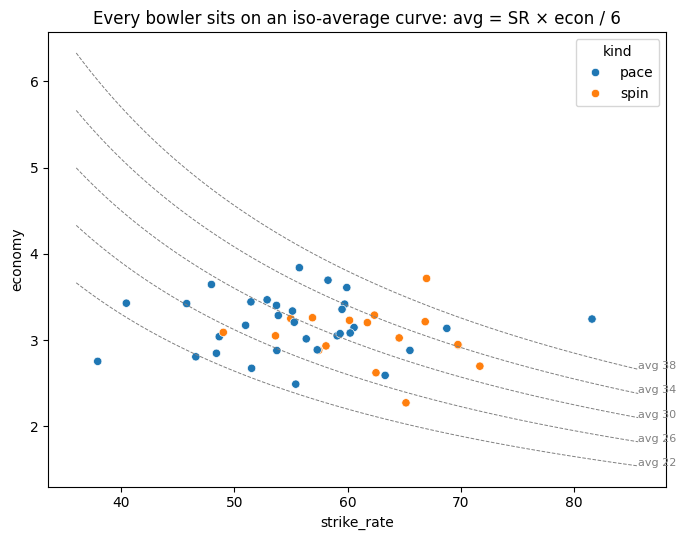

In [17]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.scatterplot(main.assign(kind=np.where(main.is_spinner == 1, 'spin', 'pace')), x='strike_rate', y='economy', hue='kind', ax=ax)
sr_grid = np.linspace(main.strike_rate.min() * 0.95, main.strike_rate.max() * 1.05, 100)
for a in [22, 26, 30, 34, 38]:
    ax.plot(sr_grid, 6 * a / sr_grid, color='grey', lw=0.7, ls='--')
    ax.text(sr_grid[-1], 6 * a / sr_grid[-1], f'avg {a}', fontsize=8, color='grey')
ax.set_title('Every bowler sits on an iso-average curve: avg = SR × econ / 6')
plt.tight_layout()

### 5.2 One feature at a time
For each feature: the Spearman correlation with the average, a bootstrap 95% CI, and a Benjamini–Hochberg q-value across all features tested.
A **negative** ρ means more of the feature goes with a **lower (better)** average.
Features that are arithmetically tied to the average are flagged `mechanical`: SR, economy, matches-to-100, overs-to-100, dot%, boundary% and maidens.
The dismissed batter's score, balls faced and SR *in that innings* are flagged `outcome-adjacent`. Those runs were partly scored off this bowler, so a high value is partly the high average itself rather than a cause of it.

In [18]:
FEATURES = {
    # hypothesis id: (column, label, group)
    'H2':  ('lhb_wicket_pct', '% wickets vs left-handers', 'who they dismiss'),
    'H2b': ('lhb_wicket_minus_exposure', 'LHB wicket % minus LHB ball %', 'who they dismiss'),
    'H3a': ('top-order_wicket_pct', '% wickets top order (1-3)', 'who they dismiss'),
    'H3b': ('middle-order_wicket_pct', '% wickets middle order (4-7)', 'who they dismiss'),
    'H3c': ('tailender_wicket_pct', '% wickets tail (8-11)', 'who they dismiss'),
    'H4a': ('caught_pct', '% caught (by fielder)', 'how they dismiss'),
    'H4b': ('bowled_pct', '% bowled', 'how they dismiss'),
    'H4c': ('lbw_pct', '% lbw', 'how they dismiss'),
    'H4d': ('bowled_or_lbw_pct', '% bowled or lbw', 'how they dismiss'),
    'H4e': ('stumped_pct', '% stumped', 'how they dismiss'),
    'H4f': ('caught_and_bowled_pct', '% caught & bowled', 'how they dismiss'),
    'H5':  ('matches_to_100', 'Matches to 100 wickets', 'mechanical'),
    'H6':  ('dismissed_batter_age', 'Avg age of batters dismissed', 'who they dismiss'),
    'H7a': ('wides_per_100', 'Wides per 100 deliveries', 'discipline'),
    'H7b': ('noballs_per_100', 'No-balls per 100 deliveries', 'discipline'),
    'H7c': ('byes_per_100', 'Byes per 100 deliveries', 'discipline'),
    'H7d': ('legbyes_per_100', 'Leg-byes per 100 deliveries', 'discipline'),
    'H8':  ('second_bowling_innings_wicket_pct', "% wickets in bowler's 2nd innings", 'match situation'),
    'H9':  ('age_at_first_test', 'Age at first Test', 'bowler profile'),
    'H10': ('bowler_bats_left', 'Bowler bats left-handed', 'bowler profile'),
    'H11': ('unique_opponents', 'Distinct opponents', 'context'),
    'H12': ('strike_rate', 'Strike rate', 'mechanical'),
    'H13': ('overs_to_100', 'Overs to 100 wickets', 'mechanical'),
    'H14': ('dismissed_batter_career_sr', 'Dismissed batters: career SR', 'who they dismiss'),
    'H15': ('dismissed_batter_career_avg', 'Dismissed batters: career avg', 'who they dismiss'),
    'H15b': ('quality_wicket_pct', '% wickets of batters avg ≥ 40', 'who they dismiss'),
    'H16': ('dismissed_batter_innings_sr', 'Dismissed batters: SR in that innings', 'outcome-adjacent'),
    'H17': ('dismissed_batter_innings_runs', 'Dismissed batters: runs in that innings', 'outcome-adjacent'),
    'H18': ('dismissed_batter_innings_balls', 'Dismissed batters: balls faced in that innings', 'outcome-adjacent'),
    'H19': ('dismissed_batter_prior_tests', 'Dismissed batters: prior Tests', 'who they dismiss'),
    'X1':  ('is_spinner', 'Spinner (vs pace)', 'bowler profile'),
    'X2':  ('is_left_arm', 'Left-arm bowler', 'bowler profile'),
    'X3':  ('economy', 'Economy rate', 'mechanical'),
    'X4':  ('dot_ball_pct', 'Dot-ball %', 'mechanical'),
    'X5':  ('boundary_pct', 'Boundary % of legal balls', 'mechanical'),
    'X6':  ('maiden_rate', 'Maiden rate (per over)', 'mechanical'),
    'X7':  ('balls_per_match', 'Balls bowled per match', 'workload'),
    'X8':  ('team_ball_share_pct', "Share of team's balls bowled", 'workload'),
    'X9':  ('debut_year', 'First Test year (era)', 'context'),
    'X10': ('match_env_avg', 'Match environment: others\' runs/wkt', 'context'),
    'X11': ('venue_env_avg', 'Venue environment: runs/wkt', 'context'),
    'X12': ('opposition_batting_avg', 'Opposition batting runs/wkt', 'context'),
    'X13': ('team_win_pct', 'Team win %', 'context'),
    'X14': ('team_draw_pct', 'Team draw %', 'context'),
}


def boot_spearman(x, y, n_boot=N_BOOT, rng=RNG):
    x, y = np.asarray(x), np.asarray(y)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    rho, p = stats.spearmanr(x, y)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    boots = np.array([stats.spearmanr(x[i], y[i])[0] for i in idx])
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return rho, lo, hi, p, len(x)


def bh_qvalues(p):
    p = np.asarray(p, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)   # constant features (e.g. 'spinner' inside the spin-only subset) have no p-value
    pv = p[ok]
    order = np.argsort(pv)
    ranked = pv[order] * len(pv) / (np.arange(len(pv)) + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    q_sorted = np.empty_like(q)
    q_sorted[order] = np.minimum(q, 1)
    out[ok] = q_sorted
    return out


def univariate_table(frame, target='average'):
    rows = []
    for hid, (col, label, group) in FEATURES.items():
        if frame[col].nunique() < 2:
            rows.append({'id': hid, 'feature': col, 'label': label, 'group': group, 'n': len(frame), 'rho': np.nan, 'ci_low': np.nan, 'ci_high': np.nan, 'p': np.nan})
            continue
        rho, lo, hi, p, n = boot_spearman(frame[col], frame[target])
        rows.append({'id': hid, 'feature': col, 'label': label, 'group': group, 'n': n, 'rho': rho, 'ci_low': lo, 'ci_high': hi, 'p': p})
    out = pd.DataFrame(rows)
    out['q'] = bh_qvalues(out['p'])
    return out.sort_values('rho').reset_index(drop=True)


uni = univariate_table(main)
uni.round(3)

,id,feature,label,group,n,rho,ci_low,ci_high,p,q
0,X4,dot_ball_pct,Dot-ball %,mechanical,49,-0.611,-0.772,-0.370,0.000,0.000
1,X6,maiden_rate,Maiden rate (per over),mechanical,49,-0.557,-0.726,-0.324,0.000,0.000
2,X8,team_ball_share_pct,Share of team's balls bowled,workload,49,-0.285,-0.514,-0.010,0.047,0.187
3,H19,dismissed_batter_prior_tests,Dismissed batters: prior Tests,who they dismiss,49,-0.270,-0.524,0.030,0.061,0.214
4,H8,second_bowling_innings_wicket_pct,% wickets in bowler's 2nd innings,match situation,49,-0.266,-0.515,0.019,0.065,0.214
5,X13,team_win_pct,Team win %,context,49,-0.263,-0.535,0.044,0.068,0.214
6,H7b,noballs_per_100,No-balls per 100 deliveries,discipline,49,-0.213,-0.477,0.075,0.141,0.345
7,H9,age_at_first_test,Age at first Test,bowler profile,49,-0.176,-0.477,0.137,0.226,0.497
8,H7d,legbyes_per_100,Leg-byes per 100 deliveries,discipline,49,-0.160,-0.427,0.111,0.273,0.515
9,X9,debut_year,First Test year (era),context,49,-0.154,-0.421,0.153,0.289,0.515


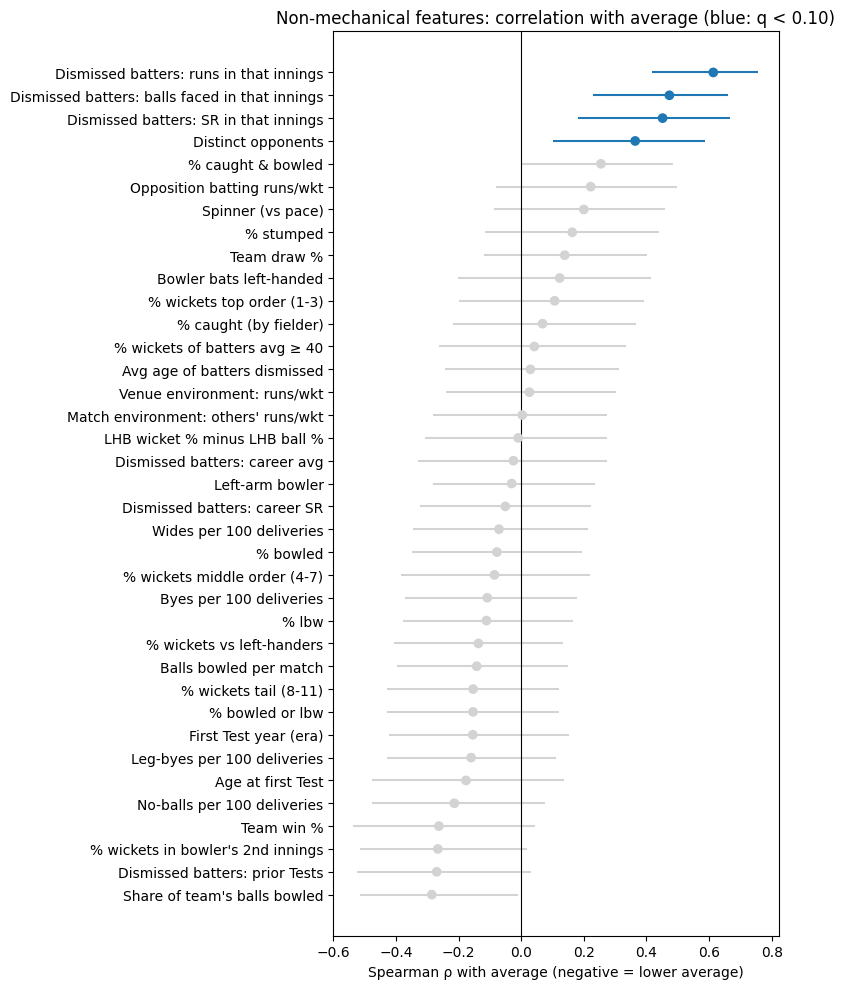

In [19]:
plot_df = uni[uni['group'] != 'mechanical'].sort_values('rho')
fig, ax = plt.subplots(figsize=(8, 10))
colors = np.where(plot_df['q'] < 0.1, 'tab:blue', 'lightgrey')
ax.hlines(range(len(plot_df)), plot_df['ci_low'], plot_df['ci_high'], color=colors)
ax.scatter(plot_df['rho'], range(len(plot_df)), color=colors, zorder=3)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df['label'])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Spearman ρ with average (negative = lower average)')
ax.set_title('Non-mechanical features: correlation with average (blue: q < 0.10)')
plt.tight_layout()

#### Profile by average tertile
Medians of key features for the best, middle and worst third of bowlers by average. This is easier to read than ρ.

In [20]:
TERTILE_COLS = ['average', 'strike_rate', 'economy', 'matches_to_100', 'dot_ball_pct', 'boundary_pct', 'team_ball_share_pct',
                'second_bowling_innings_wicket_pct', 'dismissed_batter_innings_runs', 'dismissed_batter_innings_balls',
                'dismissed_batter_career_avg', 'top-order_wicket_pct', 'tailender_wicket_pct', 'bowled_or_lbw_pct',
                'match_env_avg', 'opposition_batting_avg', 'team_win_pct', 'is_spinner']
main['avg_tertile'] = pd.qcut(main['average'], 3, labels=['lowest third', 'middle third', 'highest third'])
tertiles = main.groupby('avg_tertile', observed=True)[TERTILE_COLS].median().T
tertiles.loc['is_spinner'] = main.groupby('avg_tertile', observed=True)['is_spinner'].mean().values   # share of spinners
tertiles.round(2)

avg_tertile,lowest third,middle third,highest third
average,25.24,30.22,34.23
strike_rate,51.52,55.82,63.46
economy,2.88,3.23,3.24
matches_to_100,24.00,28.00,32.00
dot_ball_pct,77.95,75.81,72.61
boundary_pct,5.89,7.19,6.14
team_ball_share_pct,22.61,20.77,21.38
second_bowling_innings_wicket_pct,42.00,38.00,39.00
dismissed_batter_innings_runs,22.69,24.71,28.55
dismissed_batter_innings_balls,47.53,48.01,54.36


#### Partial correlations: is a signal just a confounder?
Some features probably ride on something else:
* the distinct-opponent count rises with the number of matches played;
* dismissed batters' prior Tests and the era are both shaped by when the data starts;
* workload share and team win % may reflect that captains bowl, and teams win with, their best bowler.

A partial Spearman correlation ranks every variable, regresses the control(s) out of both sides, then correlates the residuals.

In [21]:
def partial_spearman(frame, x, y, controls, n_boot=N_BOOT, rng=RNG):
    d = frame[[x, y] + controls].dropna().rank()
    def resid_corr(sub):
        C = np.column_stack([np.ones(len(sub)), sub[controls].values])
        rx = sub[x].values - C @ np.linalg.lstsq(C, sub[x].values, rcond=None)[0]
        ry = sub[y].values - C @ np.linalg.lstsq(C, sub[y].values, rcond=None)[0]
        return np.corrcoef(rx, ry)[0, 1]
    r = resid_corr(d)
    boots = [resid_corr(d.iloc[rng.integers(0, len(d), len(d))]) for _ in range(n_boot)]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return r, lo, hi

partial_specs = [
    ('unique_opponents', ['matches_to_100']),
    ('dismissed_batter_prior_tests', ['debut_year']),
    ('team_ball_share_pct', ['is_spinner']),
    ('team_ball_share_pct', ['team_win_pct']),
    ('team_win_pct', ['team_ball_share_pct']),
    ('second_bowling_innings_wicket_pct', ['is_spinner']),
    ('is_spinner', ['debut_year']),
]
partials = []
for x, ctrl in partial_specs:
    r, lo, hi = partial_spearman(main, x, 'average', ctrl)
    partials.append({'feature': x, 'controls': ', '.join(ctrl), 'raw_rho': stats.spearmanr(main[x], main['average'])[0],
                     'partial_rho': r, 'ci_low': lo, 'ci_high': hi})
partials = pd.DataFrame(partials)
partials.round(3)

,feature,controls,raw_rho,partial_rho,ci_low,ci_high
0,unique_opponents,matches_to_100,0.364,0.058,-0.181,0.320
1,dismissed_batter_prior_tests,debut_year,-0.270,-0.224,-0.491,0.077
2,team_ball_share_pct,is_spinner,-0.285,-0.622,-0.747,-0.464
3,team_ball_share_pct,team_win_pct,-0.285,-0.226,-0.460,0.041
4,team_win_pct,team_ball_share_pct,-0.263,-0.196,-0.498,0.145
5,second_bowling_innings_wicket_pct,is_spinner,-0.266,-0.386,-0.610,-0.102
6,is_spinner,debut_year,0.200,0.216,-0.066,0.475


#### Group comparisons

In [22]:
def group_compare(frame, col, target='average'):
    a = frame.loc[frame[col] == 1, target]
    b = frame.loc[frame[col] == 0, target]
    u, p = stats.mannwhitneyu(a, b)
    return pd.Series({'n_yes': len(a), 'n_no': len(b), 'median_yes': a.median(), 'median_no': b.median(),
                      'rank_biserial': 1 - 2 * u / (len(a) * len(b)), 'p': p})

group_tests = pd.DataFrame({c: group_compare(main, c) for c in ['is_spinner', 'is_left_arm', 'bowler_bats_left']}).T
group_tests.round(3)

,n_yes,n_no,median_yes,median_no,rank_biserial,p
is_spinner,17.0,32.0,32.230,29.540,-0.243,0.169
is_left_arm,14.0,35.0,29.665,30.410,0.039,0.842
bowler_bats_left,19.0,30.0,31.450,29.905,-0.146,0.400


In [23]:
type_summary = main.groupby('bowling_type')['average'].agg(['count', 'median', 'mean']).sort_values('median')
kw = stats.kruskal(*[g['average'].values for _, g in main.groupby('bowling_type') if len(g) >= 3])
print('Kruskal-Wallis across bowling types with n ≥ 3:', kw)
type_summary.round(2)

Kruskal-Wallis across bowling types with n ≥ 3: KruskalResult(statistic=np.float64(2.854054640069393), pvalue=np.float64(0.5825384211604315))


,count,median,mean
bowling_type,,,
legbreak googly,1,27.26,27.26
medium-fast,4,28.44,27.91
fast,14,29.52,28.72
fast-medium,14,30.22,30.23
orthodox,8,31.57,30.46
offbreak,7,32.55,32.07
legbreak,1,35.81,35.81


### 5.3 What drives SR, and what drives economy?
The same correlations, run separately against log SR and log economy. This shows *which half* of the average each attribute works through.

In [24]:
mech_split = []
for hid, (col, label, group) in FEATURES.items():
    if col in ('strike_rate', 'economy', 'overs_to_100', 'matches_to_100'):
        continue
    r_sr = stats.spearmanr(main[col], np.log(main['strike_rate']), nan_policy='omit')[0]
    r_ec = stats.spearmanr(main[col], np.log(main['economy']), nan_policy='omit')[0]
    r_av = stats.spearmanr(main[col], main['average'], nan_policy='omit')[0]
    mech_split.append({'id': hid, 'label': label, 'group': group, 'rho_avg': r_av, 'rho_SR': r_sr, 'rho_economy': r_ec})
mech_split = pd.DataFrame(mech_split).sort_values('rho_avg')
mech_split.round(2)

,id,label,group,rho_avg,rho_SR,rho_economy
29,X4,Dot-ball %,mechanical,-0.61,-0.20,-0.66
31,X6,Maiden rate (per over),mechanical,-0.56,-0.06,-0.76
33,X8,Share of team's balls bowled,workload,-0.29,0.09,-0.50
26,H19,Dismissed batters: prior Tests,who they dismiss,-0.27,-0.31,-0.02
16,H8,% wickets in bowler's 2nd innings,match situation,-0.27,-0.19,-0.18
38,X13,Team win %,context,-0.26,-0.21,-0.19
13,H7b,No-balls per 100 deliveries,discipline,-0.21,-0.34,0.12
17,H9,Age at first Test,bowler profile,-0.18,-0.02,-0.22
15,H7d,Leg-byes per 100 deliveries,discipline,-0.16,-0.37,0.24
34,X9,First Test year (era),context,-0.15,-0.32,0.22


### 5.4 Multivariate model
Ridge regression on standardised features, with log(average) as the target. Mechanical features are left out.
* The penalty is chosen by leave-one-out CV.
* Out-of-sample R² comes from leave-one-out predictions.
* Coefficient CIs come from 1,000 bootstrap refits at the chosen penalty.

A random forest with permutation importance is a non-linear cross-check.

In [25]:
# Model A: bowler attributes, who/how they dismiss, discipline, workload and context. No mechanical or outcome-adjacent features.
MODEL_FEATURES = [
    'is_spinner', 'is_left_arm', 'bowler_bats_left', 'age_at_first_test', 'debut_year',
    'lhb_wicket_minus_exposure', 'top-order_wicket_pct', 'tailender_wicket_pct',
    'bowled_or_lbw_pct', 'stumped_pct', 'second_bowling_innings_wicket_pct',
    'dismissed_batter_career_avg', 'dismissed_batter_prior_tests',
    'dismissed_batter_age', 'wides_per_100', 'noballs_per_100', 'byes_per_100', 'legbyes_per_100',
    'balls_per_match', 'team_ball_share_pct', 'unique_opponents',
    'match_env_avg', 'opposition_batting_avg', 'team_win_pct',
]
# Model B adds the outcome-adjacent features, to show how much they add
OUTCOME_ADJACENT = ['dismissed_batter_innings_runs', 'dismissed_batter_innings_balls', 'dismissed_batter_innings_sr']
LABELS = {col: label for col, label, _ in FEATURES.values()}

X = main[MODEL_FEATURES].astype(float)
X = X.fillna(X.median())
y = main['log_average'].values

alphas = np.logspace(-2, 3, 60)
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas))
ridge.fit(X, y)
best_alpha = ridge[-1].alpha_

loo_pred = cross_val_predict(make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)), X, y, cv=LeaveOneOut())
ridge_r2_oos = r2_score(y, loo_pred)
print(f'Ridge alpha = {best_alpha:.2f}; in-sample R² = {ridge.score(X, y):.2f}; leave-one-out R² = {ridge_r2_oos:.2f}')

boot_coefs = []
for _ in range(1000):
    i = RNG.integers(0, len(X), len(X))
    m = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)).fit(X.iloc[i], y[i])
    boot_coefs.append(m[-1].coef_)
boot_coefs = np.array(boot_coefs)

coef = pd.DataFrame({
    'feature': MODEL_FEATURES,
    'label': [LABELS.get(c, c) for c in MODEL_FEATURES],
    'coef': ridge[-1].coef_,
    'ci_low': np.percentile(boot_coefs, 2.5, axis=0),
    'ci_high': np.percentile(boot_coefs, 97.5, axis=0),
})
# Coefficient = change in log(average) per 1 SD of the feature; convert to % change in average
coef['pct_change_per_sd'] = 100 * (np.exp(coef['coef']) - 1)
coef['ci_excludes_0'] = (coef['ci_low'] > 0) | (coef['ci_high'] < 0)
coef = coef.sort_values('coef')
coef.round(3)

Ridge alpha = 20.19; in-sample R² = 0.52; leave-one-out R² = 0.14


,feature,label,coef,ci_low,ci_high,pct_change_per_sd,ci_excludes_0
19,team_ball_share_pct,Share of team's balls bowled,-0.032,-0.047,-0.009,-3.197,True
15,noballs_per_100,No-balls per 100 deliveries,-0.028,-0.054,0.000,-2.792,False
10,second_bowling_innings_wicket_pct,% wickets in bowler's 2nd innings,-0.026,-0.048,0.004,-2.595,False
12,dismissed_batter_prior_tests,Dismissed batters: prior Tests,-0.020,-0.038,0.005,-1.995,False
17,legbyes_per_100,Leg-byes per 100 deliveries,-0.020,-0.035,0.002,-1.977,False
7,tailender_wicket_pct,% wickets tail (8-11),-0.013,-0.031,0.004,-1.250,False
3,age_at_first_test,Age at first Test,-0.011,-0.033,0.017,-1.104,False
18,balls_per_match,Balls bowled per match,-0.009,-0.025,0.009,-0.898,False
1,is_left_arm,Left-arm bowler,-0.009,-0.026,0.010,-0.891,False
23,team_win_pct,Team win %,-0.008,-0.033,0.009,-0.829,False


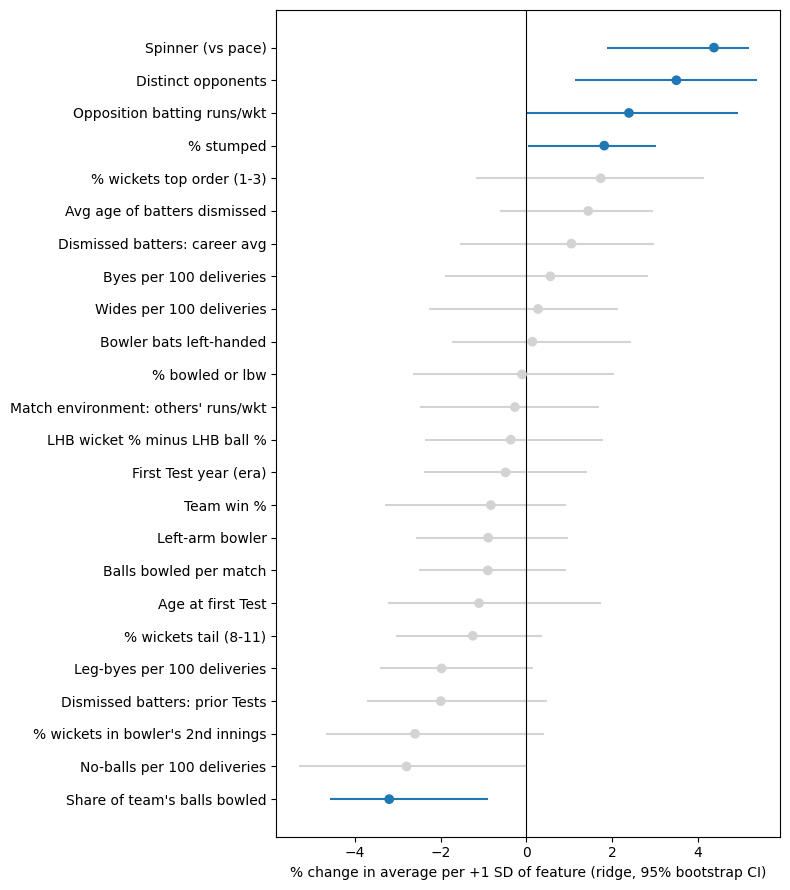

In [26]:
fig, ax = plt.subplots(figsize=(8, 9))
c = np.where(coef['ci_excludes_0'], 'tab:blue', 'lightgrey')
ax.hlines(range(len(coef)), 100 * (np.exp(coef['ci_low']) - 1), 100 * (np.exp(coef['ci_high']) - 1), color=c)
ax.scatter(coef['pct_change_per_sd'], range(len(coef)), color=c, zorder=3)
ax.set_yticks(range(len(coef)))
ax.set_yticklabels(coef['label'])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('% change in average per +1 SD of feature (ridge, 95% bootstrap CI)')
plt.tight_layout()

In [27]:
rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=42)
rf_pred = cross_val_predict(rf, X, y, cv=LeaveOneOut())
rf_r2_oos = r2_score(y, rf_pred)
print(f'Random forest leave-one-out R² = {rf_r2_oos:.2f}')

imp_rows = []
for k, (tr, te) in enumerate(RepeatedKFold(n_splits=5, n_repeats=10, random_state=42).split(X)):
    m = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=k).fit(X.iloc[tr], y[tr])
    pi = permutation_importance(m, X.iloc[te], y[te], n_repeats=5, random_state=k, scoring='neg_mean_squared_error')
    imp_rows.append(pi.importances_mean)
rf_importance = pd.DataFrame({
    'feature': MODEL_FEATURES,
    'label': [LABELS.get(c, c) for c in MODEL_FEATURES],
    'importance': np.mean(imp_rows, axis=0),
    'importance_sd': np.std(imp_rows, axis=0),
}).sort_values('importance', ascending=False)
rf_importance.head(12).round(5)

Random forest leave-one-out R² = -0.00


,feature,label,importance,importance_sd
19,team_ball_share_pct,Share of team's balls bowled,0.00269,0.00213
15,noballs_per_100,No-balls per 100 deliveries,0.00079,0.00148
17,legbyes_per_100,Leg-byes per 100 deliveries,0.00058,0.00081
20,unique_opponents,Distinct opponents,0.00054,0.00151
12,dismissed_batter_prior_tests,Dismissed batters: prior Tests,0.00040,0.00099
23,team_win_pct,Team win %,0.00013,0.00112
7,tailender_wicket_pct,% wickets tail (8-11),0.00004,0.00093
0,is_spinner,Spinner (vs pace),0.00002,0.00008
9,stumped_pct,% stumped,0.00002,0.00010
21,match_env_avg,Match environment: others' runs/wkt,0.00001,0.00038


In [28]:
XB = main[MODEL_FEATURES + OUTCOME_ADJACENT].astype(float)
XB = XB.fillna(XB.median())
ridge_b = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)).fit(XB, y)
loo_b = cross_val_predict(make_pipeline(StandardScaler(), Ridge(alpha=ridge_b[-1].alpha_)), XB, y, cv=LeaveOneOut())
ridge_b_r2_oos = r2_score(y, loo_b)
print(f'Model B (+ outcome-adjacent) ridge: alpha = {ridge_b[-1].alpha_:.2f}; leave-one-out R² = {ridge_b_r2_oos:.2f}')
pd.Series(ridge_b[-1].coef_, index=XB.columns).sort_values().round(3)

Model B (+ outcome-adjacent) ridge: alpha = 36.25; leave-one-out R² = 0.31


team_ball_share_pct                 -0.018
noballs_per_100                     -0.014
dismissed_batter_prior_tests        -0.013
second_bowling_innings_wicket_pct   -0.012
legbyes_per_100                     -0.010
is_left_arm                         -0.009
byes_per_100                        -0.008
team_win_pct                        -0.008
match_env_avg                       -0.008
age_at_first_test                   -0.007
lhb_wicket_minus_exposure           -0.005
balls_per_match                     -0.005
tailender_wicket_pct                -0.004
debut_year                          -0.003
wides_per_100                       -0.001
bowler_bats_left                     0.001
dismissed_batter_career_avg          0.002
bowled_or_lbw_pct                    0.003
stumped_pct                          0.010
top-order_wicket_pct                 0.013
opposition_batting_avg               0.016
dismissed_batter_age                 0.017
is_spinner                           0.018
unique_oppo

### 5.5 How much of a low average is the conditions?
`relative_average` = the bowler's average ÷ the runs per wicket that every other bowler conceded in the same matches.
Values below 1 mean the bowler beat the conditions they played in. The question is how far the ranking moves once conditions are taken out.

In [29]:
main['rank_raw'] = main['average'].rank()
main['rank_relative'] = main['relative_average'].rank()
main['rank_shift'] = main['rank_raw'] - main['rank_relative']
print('Spearman(raw average, match environment):', round(stats.spearmanr(main['average'], main['match_env_avg'])[0], 3))
print('Spearman(raw rank, relative rank):', round(stats.spearmanr(main['rank_raw'], main['rank_relative'])[0], 3))
adj_cols = ['bowler', 'team', 'bowling_type', 'average', 'match_env_avg', 'relative_average', 'rank_raw', 'rank_relative', 'rank_shift']
display(main.sort_values('relative_average')[adj_cols].head(10).round(2))
display(main.reindex(main['rank_shift'].abs().sort_values(ascending=False).index)[adj_cols].head(10).round(2))

Spearman(raw average, match environment): 0.004
Spearman(raw rank, relative rank): 0.842


,bowler,team,bowling_type,average,match_env_avg,relative_average,rank_raw,rank_relative,rank_shift
53,VD Philander,South Africa,fast-medium,17.40,37.13,0.47,1.0,1.0,0.0
61,PJ Cummins,Australia,fast,21.79,33.34,0.65,2.0,2.0,0.0
68,Yasir Shah,Pakistan,legbreak googly,27.26,39.95,0.68,13.0,3.0,10.0
8,RJ Harris,Australia,fast,22.97,33.06,0.69,4.0,4.0,0.0
18,Shaheen Shah Afridi,Pakistan,fast,24.65,34.21,0.72,7.0,5.0,2.0
0,JR Hazlewood,Australia,fast-medium,25.79,35.62,0.72,10.0,6.0,4.0
69,MG Johnson,Australia,fast,28.31,38.87,0.73,18.0,7.0,11.0
12,GP Swann,England,offbreak,28.39,37.99,0.75,19.0,8.0,11.0
65,K Rabada,South Africa,fast,23.11,30.78,0.75,6.0,9.0,-3.0
70,RA Jadeja,India,orthodox,24.68,32.82,0.75,8.0,10.0,-2.0


,bowler,team,bowling_type,average,match_env_avg,relative_average,rank_raw,rank_relative,rank_shift
29,PP Ojha,India,orthodox,32.23,39.60,0.81,34.0,14.0,20.0
27,I Sharma,India,fast-medium,34.02,38.82,0.88,39.0,22.0,17.0
62,JNT Seales,West Indies,fast-medium,26.12,27.99,0.93,11.0,28.0,-17.0
14,Mohammed Siraj,India,fast,30.56,27.13,1.13,28.0,44.0,-16.0
19,JJ Bumrah,India,fast,22.95,26.97,0.85,3.0,18.0,-15.0
3,KA Maharaj,South Africa,orthodox,30.91,27.89,1.11,30.0,43.0,-13.0
66,MJ Henry,New Zealand,fast-medium,30.94,35.81,0.86,31.0,20.0,11.0
36,Mohammed Shami,India,fast,30.46,36.62,0.83,27.0,16.0,11.0
6,JO Holder,West Indies,medium-fast,27.34,30.24,0.90,15.0,26.0,-11.0
69,MG Johnson,Australia,fast,28.31,38.87,0.73,18.0,7.0,11.0


In [30]:
uni_rel = univariate_table(main, target='relative_average')
uni_rel[uni_rel['group'] != 'mechanical'].round(3).head(12)

,id,feature,label,group,n,rho,ci_low,ci_high,p,q
2,X10,match_env_avg,Match environment: others' runs/wkt,context,49,-0.494,-0.694,-0.243,0.000,0.002
3,X13,team_win_pct,Team win %,context,49,-0.425,-0.658,-0.139,0.002,0.011
4,X8,team_ball_share_pct,Share of team's balls bowled,workload,49,-0.347,-0.583,-0.064,0.015,0.054
5,X11,venue_env_avg,Venue environment: runs/wkt,context,49,-0.337,-0.563,-0.073,0.018,0.060
6,X7,balls_per_match,Balls bowled per match,workload,49,-0.312,-0.542,-0.040,0.029,0.091
7,H8,second_bowling_innings_wicket_pct,% wickets in bowler's 2nd innings,match situation,49,-0.198,-0.498,0.134,0.172,0.421
8,H4d,bowled_or_lbw_pct,% bowled or lbw,how they dismiss,49,-0.167,-0.429,0.123,0.252,0.554
9,H4c,lbw_pct,% lbw,how they dismiss,49,-0.132,-0.386,0.147,0.365,0.661
10,H9,age_at_first_test,Age at first Test,bowler profile,49,-0.125,-0.413,0.193,0.391,0.661
11,H7d,legbyes_per_100,Leg-byes per 100 deliveries,discipline,49,-0.124,-0.413,0.175,0.395,0.661


### 5.6 Robustness
* **A:** add the censored bowlers back in.
* **B:** use each bowler's whole-career average in the data as the target instead.
* **C:** pace and spin bowlers separately.

In [31]:
robust = uni[['id', 'feature', 'label', 'group', 'rho', 'q']].rename(columns={'rho': 'rho_main', 'q': 'q_main'})
for name, frame, target in [
    ('with_censored', feat, 'average'),
    ('career_target', main, 'career_average_in_data'),
    ('pace_only', main[main.is_spinner == 0], 'average'),
    ('spin_only', main[main.is_spinner == 1], 'average'),
]:
    t = univariate_table(frame, target)[['id', 'rho', 'q']].rename(columns={'rho': f'rho_{name}', 'q': f'q_{name}'})
    robust = robust.merge(t, on='id', how='left')
robust = robust.sort_values('rho_main')
print('Spearman(first-100 average, whole-career average in data):', round(stats.spearmanr(main['average'], main['career_average_in_data'])[0], 3))
robust.round(2)

/var/folders/z5/yxdlgv6930jbfdbkkddpr9ym0000gn/T/ipykernel_55555/2407804346.py:56: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  boots = np.array([stats.spearmanr(x[i], y[i])[0] for i in idx])


Spearman(first-100 average, whole-career average in data): 0.799


,id,feature,label,group,rho_main,q_main,rho_with_censored,q_with_censored,rho_career_target,q_career_target,rho_pace_only,q_pace_only,rho_spin_only,q_spin_only
0,X4,dot_ball_pct,Dot-ball %,mechanical,-0.61,0.00,-0.54,0.00,-0.63,0.00,-0.67,0.00,-0.49,0.18
1,X6,maiden_rate,Maiden rate (per over),mechanical,-0.56,0.00,-0.49,0.00,-0.59,0.00,-0.64,0.00,-0.42,0.26
2,X8,team_ball_share_pct,Share of team's balls bowled,workload,-0.29,0.19,-0.27,0.06,-0.23,0.29,-0.64,0.00,-0.65,0.07
3,H19,dismissed_batter_prior_tests,Dismissed batters: prior Tests,who they dismiss,-0.27,0.21,-0.18,0.30,-0.22,0.31,-0.26,0.38,-0.21,0.59
4,H8,second_bowling_innings_wicket_pct,% wickets in bowler's 2nd innings,match situation,-0.27,0.21,-0.32,0.03,-0.16,0.55,-0.43,0.06,-0.30,0.49
5,X13,team_win_pct,Team win %,context,-0.26,0.21,-0.41,0.00,-0.30,0.13,-0.20,0.43,-0.66,0.07
6,H7b,noballs_per_100,No-balls per 100 deliveries,discipline,-0.21,0.34,-0.07,0.69,-0.08,0.90,-0.14,0.64,0.09,0.82
7,H9,age_at_first_test,Age at first Test,bowler profile,-0.18,0.50,-0.30,0.04,-0.04,0.91,-0.22,0.41,-0.39,0.29
8,H7d,legbyes_per_100,Leg-byes per 100 deliveries,discipline,-0.16,0.52,-0.15,0.34,-0.23,0.29,0.05,0.86,-0.14,0.73
9,X9,debut_year,First Test year (era),context,-0.15,0.52,-0.19,0.27,-0.04,0.91,-0.25,0.39,-0.05,0.87


### 5.7 Spot-checks against published figures
The published averages at 100 Test wickets should be close. Differences come from Tests missing from Cricsheet.

In [32]:
spot = feat[feat['bowler'].isin(['JM Anderson', 'DW Steyn', 'R Ashwin', 'PJ Cummins', 'NM Lyon', 'K Rabada', 'JJ Bumrah', 'RA Jadeja'])].copy()
spot['first_test'] = spot['first_test_in_data'].dt.date.astype(str)
spot[['bowler', 'first_test', 'matches_to_100', 'average', 'strike_rate', 'economy', 'censored']].round(2)

,bowler,first_test,matches_to_100,average,strike_rate,economy,censored
19,JJ Bumrah,2018-01-05,24,22.95,51.52,2.67,0
21,R Ashwin,2011-11-06,18,27.60,57.45,2.88,0
38,DW Steyn,2006-04-15,18,19.73,33.68,3.51,1
40,NM Lyon,2011-08-31,29,32.55,64.56,3.03,0
54,JM Anderson,2003-07-24,30,36.32,62.61,3.48,1
61,PJ Cummins,2011-11-17,21,21.79,46.59,2.81,0
65,K Rabada,2015-11-05,21,23.11,40.45,3.43,0
70,RA Jadeja,2012-12-13,24,24.68,65.16,2.27,0


### 5.8 Export results for the report

In [33]:
report = {
    'n_tests': int(len(matches)),
    'date_range': [str(df['date'].min().date()), str(df['date'].max().date())],
    'coverage': coverage.reset_index().to_dict(orient='records'),
    'n_bowlers_all': int(len(feat)),
    'n_main': int(len(main)),
    'censored': feat.loc[feat['censored'] == 1, ['bowler', 'first_test_in_data']].assign(first_test_in_data=lambda x: x['first_test_in_data'].dt.date.astype(str)).to_dict(orient='records'),
    'bowlers': main[['bowler', 'team', 'bowling_type', 'is_spinner', 'is_left_arm', 'matches_to_100', 'average', 'strike_rate', 'economy',
                     'match_env_avg', 'relative_average', 'rank_raw', 'rank_relative', 'career_average_in_data']].round(3).to_dict(orient='records'),
    'decomposition': decomp.to_dict(),
    'univariate': uni.round(4).to_dict(orient='records'),
    'univariate_relative': uni_rel.round(4).to_dict(orient='records'),
    'mech_split': mech_split.round(4).to_dict(orient='records'),
    'group_tests': group_tests.round(4).reset_index().to_dict(orient='records'),
    'type_summary': type_summary.round(3).reset_index().to_dict(orient='records'),
    'ridge': {'alpha': float(best_alpha), 'r2_in': float(ridge.score(X, y)), 'r2_loo': float(ridge_r2_oos), 'coef': coef.round(4).to_dict(orient='records')},
    'ridge_b': {'alpha': float(ridge_b[-1].alpha_), 'r2_loo': float(ridge_b_r2_oos),
                'coef': pd.Series(ridge_b[-1].coef_, index=XB.columns).round(4).to_dict()},
    'partials': partials.round(4).to_dict(orient='records'),
    'tertiles': tertiles.round(3).to_dict(),
    'spearman_first100_vs_career': float(stats.spearmanr(main['average'], main['career_average_in_data'])[0]),
    'spearman_avg_matchenv': float(stats.spearmanr(main['average'], main['match_env_avg'])[0]),
    'spearman_rank_raw_relative': float(stats.spearmanr(main['rank_raw'], main['rank_relative'])[0]),
    'pace_spin': main.assign(kind=np.where(main.is_spinner == 1, 'spin', 'pace')).groupby('kind')[['average', 'strike_rate', 'economy']].median().round(3).to_dict(orient='index'),
    'rf': {'r2_loo': float(rf_r2_oos), 'importance': rf_importance.round(6).to_dict(orient='records')},
    'robust': robust.round(4).to_dict(orient='records'),
    'spot': spot[['bowler', 'matches_to_100', 'average', 'strike_rate', 'economy', 'censored']].round(2).to_dict(orient='records'),
}
with open('report_results.json', 'w') as f:
    json.dump(report, f, indent=1, default=str)
print('Saved report_results.json')

Saved report_results.json
